# Modelo de irrigação — classificação "irrigar ou não"

Continuação do EDA03 (`codes/linha3 - umidade/eda_linha3`). Aqui o objetivo é treinar, validar e exportar o modelo que vai rodar no protótipo em Fortaleza.

**Antes de rodar:** execute o notebook do EDA03. Este notebook usa os arquivos que ele gera em `outputs/eda03_linha3/`. As saídas daqui vão para `outputs/modelo_linha3/`.

## Decisões do modelo

**Alvo.** `1` se um episódio de irrigação começa nos próximos 60 min, `0` caso contrário. Só são usados os instantes com a válvula fechada, dentro da fase automática do controlador. O modelo antecipa a decisão em vez de só copiar o limiar.

**Features relativas, não absolutas.** O protótipo vai usar um sensor capacitivo v1.2, outro solo e outro clima. Um valor como "33,9%" do sensor italiano não significa nada lá. Por isso a umidade entra no modelo como posição dentro da faixa útil do solo:

$$\text{dist\_limiar} = \frac{\text{umidade} - \text{limiar}}{\text{escala}}$$

- **limiar:** valor em que a irrigação deve começar;
- **escala:** distância entre o limiar e a umidade logo depois de irrigar, ou seja, o tamanho da faixa útil. Em Fortaleza, os dois saem da calibração do sensor (seção 9).

As tendências da umidade são divididas pela mesma escala. A hora entra como **hora solar**, calculada a partir da longitude: meio-dia solar em Parma e meio-dia solar em Fortaleza representam a mesma situação.

**Dados.** Linha 3 de Parma, 2024 e 2025. Cada ano usa o sensor que o controlador usava (30 cm em 2024, 15 cm em 2025), com o seu próprio limiar.

## 0. Configuração

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

BASE_DIR = Path.cwd().resolve()
while not (BASE_DIR / "data").is_dir() and BASE_DIR != BASE_DIR.parent:
    BASE_DIR = BASE_DIR.parent

EDA_DIR = BASE_DIR / "outputs" / "eda03_linha3"
OUTPUT_DIR = BASE_DIR / "outputs" / "modelo_linha3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ESP32_DIR = BASE_DIR / "codes" / "linha3 - umidade" / "modelo_linha3" / "esp32_irrigacao"

FUSO_PARMA = "Europe/Rome"
LONGITUDE_PARMA = 10.27
LONGITUDE_FORTALEZA = -38.54

HORIZONTE_MIN = 60   # o alvo olha 60 min à frente
JANELA_PICO_MIN = 120  # janela para medir a umidade logo após irrigar

In [2]:
def salvar_fig(fig, nome):
    fig.savefig(OUTPUT_DIR / nome, dpi=150, bbox_inches="tight")


def vpd(temp, ur):
    """Déficit de pressão de vapor do ar (kPa), equação de Tetens."""
    es = 0.6108 * np.exp(17.27 * temp / (temp + 237.3))
    return es * (1 - ur / 100)

## 1. Dados

Saídas do EDA03: a série de 10 em 10 min, os pulsos de irrigação e a regra do controlador (sensor, limiar e período da fase automática de cada ano).

In [3]:
serie = pd.read_csv(EDA_DIR / "04_serie_integrada_linha3_10min.csv")
serie["datetime"] = pd.to_datetime(serie["datetime"], utc=True).dt.tz_convert(FUSO_PARMA)
serie = serie.set_index("datetime")

pulsos = pd.read_csv(EDA_DIR / "05_pulsos_irrigacao_linha3.csv")
pulsos["inicio"] = pd.to_datetime(pulsos["inicio"], utc=True).dt.tz_convert(FUSO_PARMA)

regra = pd.read_csv(EDA_DIR / "06_regra_controlador.csv")
for col in ["fase_inicio", "fase_fim"]:
    regra[col] = pd.to_datetime(regra[col], utc=True).dt.tz_convert(FUSO_PARMA)
regra = regra.set_index("ano")

ANOS = list(regra.index)
regra

,sensor,limiar,fase_inicio,fase_fim
ano,,,,
2024,30cm,26.9,2024-08-04 00:00:00+02:00,2024-09-03 23:59:59+02:00
2025,15cm,33.9,2025-07-23 00:00:00+02:00,2025-08-19 23:59:59+02:00


## 2. Escala de cada ano

A escala é a mediana de (umidade máxima nas 2 h depois do início de um episódio − limiar), considerando os episódios da fase automática. É o "quanto a umidade sobe acima do limiar quando se irriga".

In [4]:
inicios_ep = pulsos.groupby("episodio").agg(inicio=("inicio", "min"), ano=("ano", "first"))
inicios_ep["inicio"] = inicios_ep["inicio"].dt.floor("10min")

escalas = []
for ano, r in regra.iterrows():
    u = serie.loc[serie["ano"] == ano, f"umidade_{r['sensor']}"]
    eps = inicios_ep[(inicios_ep["ano"] == ano) & inicios_ep["inicio"].between(r["fase_inicio"], r["fase_fim"])]
    picos = [u.loc[t:t + pd.Timedelta(minutes=JANELA_PICO_MIN)].max() for t in eps["inicio"]]
    escalas.append({"ano": ano, "sensor": r["sensor"], "limiar": r["limiar"],
                    "pico_mediano": np.nanmedian(picos), "episodios": len(eps)})

escalas = pd.DataFrame(escalas).set_index("ano")
escalas["escala"] = escalas["pico_mediano"] - escalas["limiar"]
regra = regra.join(escalas[["escala"]])
escalas

,sensor,limiar,pico_mediano,episodios,escala
ano,,,,,
2024,30cm,26.9,35.13,39,8.23
2025,15cm,33.9,46.43,54,12.53


Em 2024, com o sensor de 30 cm, a umidade sobe de 26,9% para ~35,1% depois de irrigar: escala de 8,2 pontos. Em 2025, com o sensor de 15 cm, sobe de 33,9% para ~46,4%: escala de 12,5 pontos.

## 3. Features e alvo

A função `montar_features` é a mesma que o protótipo vai usar. Ela recebe uma tabela em grade de 10 min com `umidade`, `ar_temperatura`, `ar_umidade` e `valvula`, mais o limiar, a escala e a longitude do local.

In [5]:
FEATURES = [
    "dist_limiar",
    "tend_30min", "tend_60min", "tend_180min",
    "ar_temperatura", "ar_umidade", "vpd_kpa",
    "hora_solar_sin", "hora_solar_cos",
    "horas_desde_irrigacao",
]


def montar_features(df, limiar, escala, longitude):
    """df: grade regular de 10 min, índice com fuso, colunas umidade, ar_temperatura, ar_umidade, valvula."""
    f = pd.DataFrame(index=df.index)
    u = df["umidade"]

    f["dist_limiar"] = (u - limiar) / escala
    for m in (30, 60, 180):
        f[f"tend_{m}min"] = u.diff(m // 10) / escala

    f["ar_temperatura"] = df["ar_temperatura"]
    f["ar_umidade"] = df["ar_umidade"]
    f["vpd_kpa"] = vpd(df["ar_temperatura"], df["ar_umidade"])

    utc = df.index.tz_convert("UTC")
    hora_solar = (utc.hour + utc.minute / 60 + longitude / 15) % 24
    f["hora_solar_sin"] = np.sin(2 * np.pi * hora_solar / 24)
    f["hora_solar_cos"] = np.cos(2 * np.pi * hora_solar / 24)

    ultima = pd.Series(df.index.where(df["valvula"].fillna(0) > 0), index=df.index).ffill()
    f["horas_desde_irrigacao"] = ((df.index - ultima).dt.total_seconds() / 3600).fillna(48).clip(upper=48)

    return f[FEATURES]

In [6]:
partes = []

for ano, r in regra.iterrows():
    s = serie[serie["ano"] == ano]
    entrada = pd.DataFrame({
        "umidade": s[f"umidade_{r['sensor']}"],
        "ar_temperatura": s["ar_temperatura"],
        "ar_umidade": s["ar_umidade"],
        "valvula": s["valvula"],
    })
    f = montar_features(entrada, r["limiar"], r["escala"], LONGITUDE_PARMA)

    comeca = pd.Series(s.index.isin(inicios_ep.loc[inicios_ep["ano"] == ano, "inicio"]), index=s.index).astype(int)
    passos = HORIZONTE_MIN // 10
    f["alvo"] = comeca[::-1].rolling(passos, min_periods=1).max()[::-1].shift(-1).fillna(0).astype(int)

    f["ano"] = ano
    f["dia"] = s.index.date
    f["umidade"] = entrada["umidade"]
    f["valvula"] = s["valvula"].fillna(0)
    f["usar"] = s["valido"] & (f["valvula"] == 0) & (s.index >= r["fase_inicio"]) & (s.index <= r["fase_fim"])
    partes.append(f)

completo = pd.concat(partes)
dados = completo[completo["usar"]].dropna(subset=FEATURES)

dados.groupby("ano")["alvo"].agg(instantes="size", positivos="sum", pct_positivos=lambda x: 100 * x.mean())

,instantes,positivos,pct_positivos
ano,,,
2024,3745,212,5.661
2025,3507,291,8.298


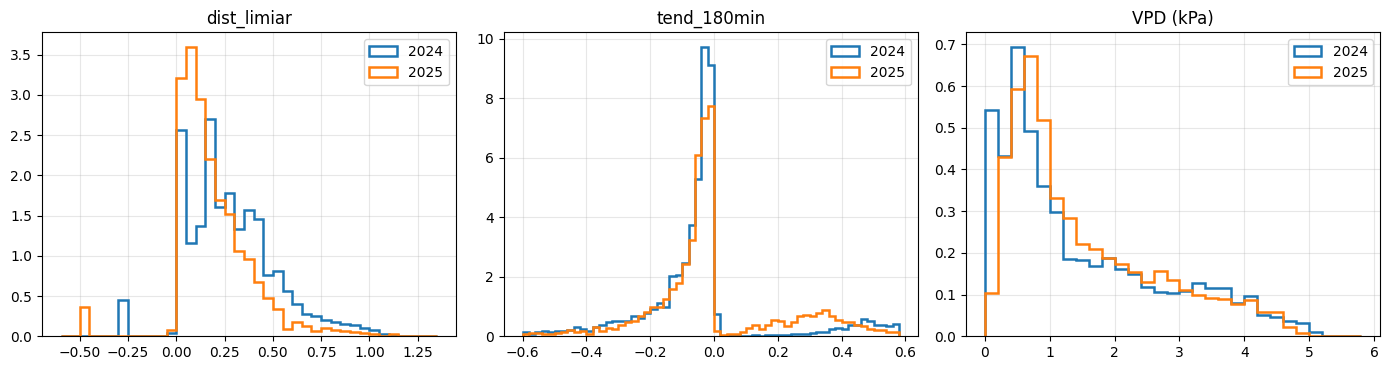

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))

for ano, g in dados.groupby("ano"):
    eixos[0].hist(g["dist_limiar"], bins=np.arange(-0.6, 1.4, 0.05), histtype="step", lw=1.8, density=True, label=str(ano))
    eixos[1].hist(g["tend_180min"], bins=np.arange(-0.6, 0.6, 0.02), histtype="step", lw=1.8, density=True, label=str(ano))
    eixos[2].hist(g["vpd_kpa"], bins=np.arange(0, 6, 0.2), histtype="step", lw=1.8, density=True, label=str(ano))

for ax, titulo in zip(eixos, ["dist_limiar", "tend_180min", "VPD (kPa)"]):
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
salvar_fig(fig, "03_distribuicao_features.png")
plt.show()

São 3.745 instantes em 2024 (212 positivos, 5,7%) e 3.507 em 2025 (291 positivos, 8,3%).

Depois da normalização, `dist_limiar` e a tendência têm distribuições parecidas nos dois anos, mesmo vindo de sensores, profundidades e limiares diferentes. É isso que permite juntar os dois anos no treino e, mais adiante, usar o modelo com outro sensor.

## 4. Validação

**Blocos de dias.** Cada fase automática é dividida em 4 blocos de dias consecutivos (8 blocos no total). O modelo é treinado com 7 blocos e testado no que sobrou, até cada bloco ter sido teste uma vez. Embaralhar instantes de 10 min misturaria treino e teste do mesmo dia e inflaria o resultado.

**Modelos comparados:**

- **regra: limiar:** irriga quando `dist_limiar` fica abaixo de um valor. É o que o controlador faz;
- **regra: tendência:** projeta a umidade daqui a 60 min com a tendência da última hora (`dist_limiar + tend_60min`). É a antecipação mais simples possível;
- **regressão logística**, **random forest** e **gradient boosting**.

**Métricas:**

- **AUC** e **AP** (área sob a curva precisão × recall; melhor que a AUC quando os positivos são poucos);
- **precisão, recall e F1** no ponto de corte que maximiza o F1;
- **por evento:** % das irrigações avisadas com antecedência, antecedência mediana e alarmes falsos por dia. São as que importam na prática.

In [8]:
def blocos_de_dias(df, n_blocos=4):
    """Divide os dias de cada ano em n blocos consecutivos."""
    grupo = pd.Series(index=df.index, dtype=object)
    for ano, g in df.groupby("ano"):
        dias = sorted(g["dia"].unique())
        mapa = {d: f"{ano}_b{min(i * n_blocos // len(dias), n_blocos - 1)}" for i, d in enumerate(dias)}
        grupo.loc[g.index] = g["dia"].map(mapa)
    return grupo


MODELOS = {
    "regressão logística": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=0),
    "gradient boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, class_weight="balanced", random_state=0),
}

REGRAS = {
    "regra: limiar": lambda X: -X["dist_limiar"],
    "regra: tendência": lambda X: -(X["dist_limiar"] + X["tend_60min"]),
}


def previsao_fora_da_amostra(modelo, X, y, grupos):
    """Score de cada instante dado por um modelo que não o viu no treino."""
    score = pd.Series(np.nan, index=X.index)
    for g in grupos.unique():
        teste = grupos == g
        m = clone(modelo).fit(X[~teste], y[~teste])
        score[teste] = m.predict_proba(X[teste])[:, 1]
    return score


def corte_f1(y, score):
    p, r, t = precision_recall_curve(y, score)
    f1 = 2 * p * r / np.clip(p + r, 1e-9, None)
    return t[np.argmax(f1[:-1])]

In [9]:
def metricas_evento(df, pred, horizonte=HORIZONTE_MIN):
    """Avalia os alarmes como eventos, ano a ano."""
    antecipados, antecedencias, falsos, dias = 0, [], 0, 0
    total = 0

    for ano, g in df.groupby("ano"):
        p = pd.Series(pred[g.index], index=g.index).sort_index()
        inicios = inicios_ep.loc[(inicios_ep["ano"] == ano) & inicios_ep["inicio"].between(g.index.min(), g.index.max()), "inicio"]
        h = pd.Timedelta(minutes=horizonte)

        for t in inicios:
            janela = p[(p.index >= t - h) & (p.index < t)]
            if janela.empty:
                continue
            total += 1
            if janela.any():
                antecipados += 1
                antecedencias.append((t - janela[janela == 1].index.min()).total_seconds() / 60)

        # alarme = início de uma sequência de previsões positivas
        novo = (p == 1) & ((p.shift(fill_value=0) == 0) | (p.index.to_series().diff() > pd.Timedelta("10min")))
        for a in p.index[novo]:
            if not ((inicios > a) & (inicios <= a + h)).any():
                falsos += 1

        dias += g["dia"].nunique()

    return {
        "% irrigações avisadas": 100 * antecipados / total if total else np.nan,
        "antecedência mediana (min)": np.median(antecedencias) if antecedencias else np.nan,
        "alarmes falsos por dia": falsos / dias,
    }


def resumo(nome, y, score, corte, df):
    pred = (score >= corte).astype(int)
    return {
        "modelo": nome,
        "AUC": roc_auc_score(y, score),
        "AP": average_precision_score(y, score),
        "precisão": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        **metricas_evento(df, pred),
    }

In [10]:
X, y = dados[FEATURES], dados["alvo"]
grupos = blocos_de_dias(dados)

scores_oof = {nome: regra_fn(X) for nome, regra_fn in REGRAS.items()}
for nome, modelo in MODELOS.items():
    scores_oof[nome] = previsao_fora_da_amostra(modelo, X, y, grupos)

comparacao = pd.DataFrame([
    resumo(nome, y, score, corte_f1(y, score), dados) for nome, score in scores_oof.items()
]).set_index("modelo")

comparacao.to_csv(OUTPUT_DIR / "04_comparacao_modelos.csv")
comparacao

,AUC,AP,precisão,recall,F1,% irrigações avisadas,antecedência mediana (min),alarmes falsos por dia
modelo,,,,,,,,
regra: limiar,0.935,0.401,0.472,0.618,0.535,97.778,35.0,0.759
regra: tendência,0.950,0.394,0.479,0.903,0.626,98.889,60.0,2.293
regressão logística,0.954,0.474,0.530,0.835,0.648,90.000,60.0,1.293
random forest,0.982,0.829,0.751,0.738,0.744,83.333,60.0,0.897
gradient boosting,0.987,0.874,0.770,0.805,0.787,91.111,60.0,0.879


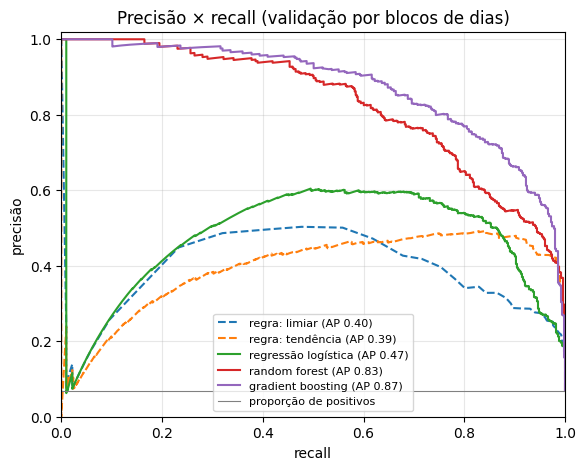

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5))

for nome, score in scores_oof.items():
    p, r, _ = precision_recall_curve(y, score)
    ax.plot(r, p, label=f"{nome} (AP {average_precision_score(y, score):.2f})", ls="--" if nome.startswith("regra") else "-")

ax.axhline(y.mean(), color="0.5", lw=0.8, label="proporção de positivos")
ax.set(xlabel="recall", ylabel="precisão", title="Precisão × recall (validação por blocos de dias)", xlim=(0, 1), ylim=(0, 1.02))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
salvar_fig(fig, "04_precisao_recall.png")
plt.show()

- O **gradient boosting** é o melhor em quase tudo: AP 0,87, F1 0,79. Avisa 91% das irrigações com 60 min de antecedência (o máximo possível, pela definição do alvo) e dá menos de 1 alarme falso por dia. O random forest fica logo atrás (AP 0,83).
- A **regressão logística** fica bem abaixo (AP 0,47). A relação não é linear: a chance de irrigar só sobe quando a umidade está bem perto do limiar e na hora certa do dia, e uma soma ponderada não representa isso.
- A **regra de limiar** avisa quase todas as irrigações, mas com só 35 min de antecedência e precisão de 0,47. A **regra de tendência** avisa 99%, mas dá 2,3 alarmes falsos por dia.

## 5. O modelo funciona num cenário que ele nunca viu?

Esse é o teste que mais se parece com levar o modelo para Fortaleza. O modelo é treinado em um ano e testado no outro. Os anos têm sensor, profundidade e limiar diferentes, e só as features relativas ligam um ao outro. O ponto de corte vem só do ano de treino.

In [12]:
linhas = []

for treino_ano, teste_ano in [(ANOS[0], ANOS[1]), (ANOS[1], ANOS[0])]:
    tr, te = dados[dados["ano"] == treino_ano], dados[dados["ano"] == teste_ano]
    g_tr = blocos_de_dias(tr)

    for nome, regra_fn in REGRAS.items():
        corte = corte_f1(tr["alvo"], regra_fn(tr[FEATURES]))
        linhas.append({"treino → teste": f"{treino_ano} → {teste_ano}",
                       **resumo(nome, te["alvo"], regra_fn(te[FEATURES]), corte, te)})

    for nome, modelo in MODELOS.items():
        corte = corte_f1(tr["alvo"], previsao_fora_da_amostra(modelo, tr[FEATURES], tr["alvo"], g_tr))
        m = clone(modelo).fit(tr[FEATURES], tr["alvo"])
        score = pd.Series(m.predict_proba(te[FEATURES])[:, 1], index=te.index)
        linhas.append({"treino → teste": f"{treino_ano} → {teste_ano}", **resumo(nome, te["alvo"], score, corte, te)})

entre_anos = pd.DataFrame(linhas).set_index(["treino → teste", "modelo"])
entre_anos.to_csv(OUTPUT_DIR / "05_teste_entre_anos.csv")
entre_anos

AUC     AP  precisão  recall     F1  % irrigações avisadas  antecedência mediana (min)  alarmes falsos por dia
treino → teste modelo                                                                                                                               
2024 → 2025    regra: limiar        0.939  0.489     0.284   0.938  0.436                100.000                        60.0                   2.536
               regra: tendência     0.937  0.386     0.468   0.828  0.598                 96.226                        60.0                   2.786
               regressão logística  0.953  0.523     0.436   0.897  0.587                 92.453                        60.0                   2.321
               random forest        0.970  0.728     0.737   0.471  0.574                 60.377                        55.0                   0.643
               gradient boosting    0.984  0.860     0.713   0.801  0.754                 92.453                        60.0                   1.286
2025 → 2024    regra: limiar        0.931  0.331     0.405   0.425  0.415                 94.595                        20.0                   0.433
               regra: tendência     0.963  0.428     0.503   0.840  0.629                 97.297                        60.0                   1.133
               regressão logística  0.964  0.494     0.589   0.608  0.599                 86.486                        45.0                   0.467
               random forest        0.985  0.814     0.672   0.726  0.698                 91.892                        50.0                   0.500
               gradient boosting    0.987  0.834     0.797   0.594  0.681                 91.892                        40.0                   0.067

O gradient boosting mantém o desempenho nos dois sentidos:

- treinado em 2024 e testado em 2025: AP 0,86, F1 0,75, 92% das irrigações avisadas;
- treinado em 2025 e testado em 2024: AP 0,83, F1 0,68, 92% avisadas e quase nenhum alarme falso.

No EDA03, com umidade absoluta, o modelo de um ano não servia para o outro (F1 ≈ 0). Com as features relativas, serve. Isso não garante o funcionamento em Fortaleza, mas é o melhor indício disponível: o modelo aprendeu o comportamento em relação ao limiar, e não um valor de sensor.

O random forest é instável (no sentido 2024 → 2025 só avisa 60%) e a logística continua fraca.

## 6. Modelo final

**Escolha: gradient boosting.** Foi o melhor na validação por blocos e no teste entre anos, e é pequeno o suficiente para rodar no ESP32 (seção 7). O ponto de corte da probabilidade é o que maximiza o F1 na validação.

In [13]:
MODELO_FINAL = "gradient boosting"

modelo = clone(MODELOS[MODELO_FINAL]).fit(X, y)
CORTE = float(corte_f1(y, scores_oof[MODELO_FINAL]))

print(f"Modelo: {MODELO_FINAL}")
print(f"Ponto de corte da probabilidade: {CORTE:.3f}")
print(f"Treinado com {len(y)} instantes ({int(y.sum())} positivos)")

Modelo: gradient boosting
Ponto de corte da probabilidade: 0.827
Treinado com 7252 instantes (503 positivos)


Importância por permutação: embaralha uma feature de cada vez e mede quanto a AP cai. Quanto maior a queda, mais o modelo depende dela. É calculada nos dados de treino, então serve para entender o modelo, não para medir desempenho.

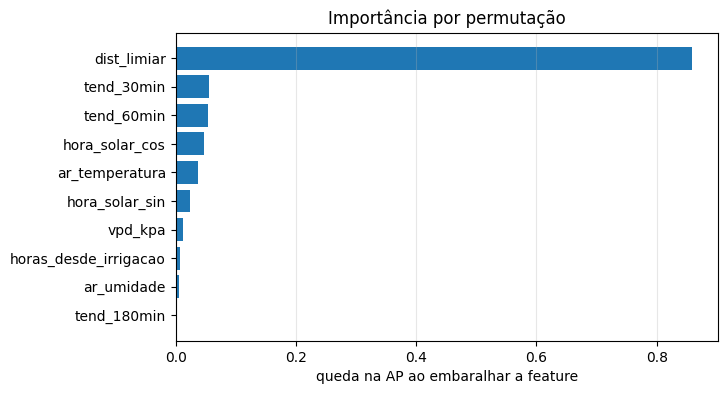

dist_limiar              0.859
tend_30min               0.056
tend_60min               0.054
hora_solar_cos           0.047
ar_temperatura           0.038
hora_solar_sin           0.024
vpd_kpa                  0.012
horas_desde_irrigacao    0.007
ar_umidade               0.006
tend_180min              0.003
dtype: float64

In [14]:
imp = permutation_importance(modelo, X, y, scoring="average_precision", n_repeats=5, random_state=0)
importancia = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importancia.index, importancia, color="tab:blue")
ax.set(title="Importância por permutação", xlabel="queda na AP ao embaralhar a feature")
ax.grid(alpha=0.3, axis="x")
salvar_fig(fig, "06_importancia.png")
plt.show()

importancia.sort_values(ascending=False).round(3)

A posição em relação ao limiar (`dist_limiar`) domina. Depois vêm a tendência da última meia hora e da última hora, a hora solar e a temperatura do ar. Umidade do ar e VPD quase não contribuem, porque o efeito do clima já aparece na velocidade com que o solo seca.

Na prática: o sensor de solo e o relógio fazem quase todo o trabalho. O BME280 ajuda pouco no modelo, mas continua útil para registrar as condições e retreinar depois.

No gráfico abaixo, a umidade fica horas logo acima do limiar, e a probabilidade só sobe nos 30 a 60 min antes de a válvula abrir.

Exemplo de funcionamento em alguns dias de 2025. A probabilidade mostrada é a da validação por blocos, ou seja, de um modelo que não tinha visto esses dias.

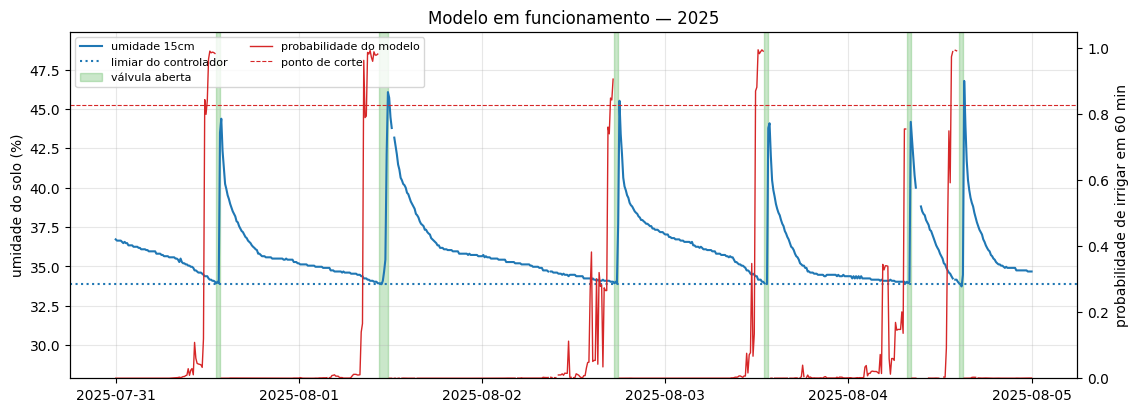

In [15]:
r25 = regra.loc[ANOS[-1]]
periodo = slice(r25["fase_inicio"] + pd.Timedelta("8D"), r25["fase_inicio"] + pd.Timedelta("13D"))

c = completo.loc[periodo]
prob = scores_oof[MODELO_FINAL].reindex(c.index)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(c.index, c["umidade"], color="tab:blue", label=f"umidade {r25['sensor']}")
ax.axhline(r25["limiar"], color="tab:blue", ls=":", label="limiar do controlador")
ax.fill_between(c.index, 0, 1, where=c["valvula"] > 0, transform=ax.get_xaxis_transform(), color="tab:green", alpha=0.25, label="válvula aberta")
ax.set_ylabel("umidade do solo (%)")
ax.set_ylim(r25["limiar"] - 6, r25["limiar"] + 16)

ax2 = ax.twinx()
ax2.plot(prob.index, prob, color="tab:red", lw=1, label="probabilidade do modelo")
ax2.axhline(CORTE, color="tab:red", ls="--", lw=0.8, label="ponto de corte")
ax2.set(ylabel="probabilidade de irrigar em 60 min", ylim=(0, 1.05))

linhas_leg = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(linhas_leg, [l.get_label() for l in linhas_leg], loc="upper left", fontsize=8, ncol=2)
ax.set_title("Modelo em funcionamento — 2025")
ax.grid(alpha=0.3)
salvar_fig(fig, "06_exemplo_funcionamento.png")
plt.show()

## 7. Exportação

O gradient boosting é uma soma de árvores de decisão pequenas. Cada árvore é só uma sequência de comparações "feature ≤ valor?", então dá para rodar no ESP32 sem servidor. São exportados:

- `modelo_irrigacao.joblib`: o modelo do scikit-learn, para usar em Python;
- `modelo_irrigacao.json`: as árvores (nós, limiares, valores) e o ponto de corte;
- `esp32_irrigacao/modelo_irrigacao.h`: as mesmas árvores em C, incluídas pelo código do ESP32.

In [16]:
def exportar_arvores(m):
    no_feat, no_lim, no_esq, no_dir, no_nan_esq, no_valor, raizes = [], [], [], [], [], [], []
    for (arvore,) in m._predictors:
        base = len(no_feat)
        raizes.append(base)
        for n in arvore.nodes:
            folha = bool(n["is_leaf"])
            no_feat.append(-1 if folha else int(n["feature_idx"]))
            no_lim.append(float(n["num_threshold"]))
            no_esq.append(-1 if folha else base + int(n["left"]))
            no_dir.append(-1 if folha else base + int(n["right"]))
            no_nan_esq.append(int(n["missing_go_to_left"]))
            no_valor.append(float(n["value"]))
    return {
        "features": FEATURES,
        "base": float(np.ravel(m._baseline_prediction)[0]),
        "raizes": raizes,
        "no_feature": no_feat, "no_limiar": no_lim, "no_esq": no_esq, "no_dir": no_dir,
        "no_nan_esq": no_nan_esq, "no_valor": no_valor,
        "ponto_de_corte": CORTE,
        "horizonte_min": HORIZONTE_MIN,
    }


def prever(X, m=None, dtype=np.float64):
    # mesma conta que o ESP32 faz: percorre cada árvore e soma o valor da folha
    m = m or exportado
    X = np.atleast_2d(np.asarray(X, dtype=dtype))
    feat, lim = np.array(m["no_feature"]), np.array(m["no_limiar"], dtype=dtype)
    esq, dir_, nan_esq = np.array(m["no_esq"]), np.array(m["no_dir"]), np.array(m["no_nan_esq"], dtype=bool)
    valor = np.array(m["no_valor"], dtype=dtype)
    linhas = np.arange(len(X))
    soma = np.full(len(X), m["base"], dtype=dtype)

    for raiz in m["raizes"]:
        no = np.full(len(X), raiz)
        while (ativos := feat[no] >= 0).any():
            n = no[ativos]
            v = X[linhas[ativos], feat[n]]
            vai_esq = np.where(np.isnan(v), nan_esq[n], v <= lim[n])
            no[ativos] = np.where(vai_esq, esq[n], dir_[n])
        soma += valor[no]

    return 1 / (1 + np.exp(-soma))


exportado = exportar_arvores(modelo)
joblib.dump(modelo, OUTPUT_DIR / "modelo_irrigacao.joblib")
(OUTPUT_DIR / "modelo_irrigacao.json").write_text(json.dumps(exportado), encoding="utf-8")

n_nos = len(exportado["no_feature"])
print(f"{len(exportado['raizes'])} árvores, {n_nos} nós, ~{n_nos * 12 / 1024:.0f} KB na memória flash do ESP32")

200 árvores, 5458 nós, ~64 KB na memória flash do ESP32


Conferência: a conta feita com os números exportados tem que dar o mesmo resultado do scikit-learn. O ESP32 usa `float` de 32 bits, então também confiro quantas decisões mudariam com essa precisão.

In [17]:
p_sklearn = modelo.predict_proba(X)[:, 1]
p_64 = prever(X.to_numpy())
p_32 = prever(X.to_numpy(), dtype=np.float32)

print(f"maior diferença (float64): {np.abs(p_64 - p_sklearn).max():.2e}")
print(f"maior diferença (float32): {np.abs(p_32 - p_sklearn).max():.2e}")
print(f"decisões diferentes em float32: {((p_32 >= CORTE) != (p_sklearn >= CORTE)).sum()} de {len(X)}")
assert np.abs(p_64 - p_sklearn).max() < 1e-9

maior diferença (float64): 2.22e-16
maior diferença (float32): 1.09e-01
decisões diferentes em float32: 0 de 7252


In [18]:
def vetor_c(tipo, nome, valores, fmt, n_linha=16):
    itens = [fmt(v) for v in valores]
    linhas = [", ".join(itens[i:i + n_linha]) for i in range(0, len(itens), n_linha)]
    return f"const {tipo} {nome}[{len(valores)}] = {{\n  " + ",\n  ".join(linhas) + "\n};"


assert n_nos < 32767

cabecalho = "\n".join([
    "// Gerado por codes/linha3 - umidade/modelo_linha3/modelo_irrigacao.ipynb. Não editar à mão.",
    "#pragma once",
    "#include <math.h>",
    "#include <stdint.h>",
    "",
    f"#define N_FEATURES {len(FEATURES)}",
    f"#define N_ARVORES {len(exportado['raizes'])}",
    f"// ordem das features: {', '.join(FEATURES)}",
    f"const float MODELO_BASE = {exportado['base']:.8f}f;",
    f"const float MODELO_CORTE = {CORTE:.6f}f;",
    "",
    vetor_c("uint16_t", "RAIZES", exportado["raizes"], str),
    vetor_c("int8_t", "NO_FEATURE", exportado["no_feature"], str),
    vetor_c("float", "NO_LIMIAR", exportado["no_limiar"], lambda v: f"{v:.9g}f"),
    vetor_c("int16_t", "NO_ESQ", exportado["no_esq"], str),
    vetor_c("int16_t", "NO_DIR", exportado["no_dir"], str),
    vetor_c("uint8_t", "NO_NAN_ESQ", exportado["no_nan_esq"], str),
    vetor_c("float", "NO_VALOR", exportado["no_valor"], lambda v: f"{v:.9g}f"),
    "",
    "// Probabilidade de começar uma irrigação nos próximos 60 min.",
    "static inline float modelo_probabilidade(const float x[N_FEATURES]) {",
    "  float soma = MODELO_BASE;",
    "  for (int a = 0; a < N_ARVORES; a++) {",
    "    int no = RAIZES[a];",
    "    while (NO_FEATURE[no] >= 0) {",
    "      float v = x[NO_FEATURE[no]];",
    "      bool esquerda = isnan(v) ? NO_NAN_ESQ[no] : (v <= NO_LIMIAR[no]);",
    "      no = esquerda ? NO_ESQ[no] : NO_DIR[no];",
    "    }",
    "    soma += NO_VALOR[no];",
    "  }",
    "  return 1.0f / (1.0f + expf(-soma));",
    "}",
    "",
])

ESP32_DIR.mkdir(parents=True, exist_ok=True)
(ESP32_DIR / "modelo_irrigacao.h").write_text(cabecalho, encoding="utf-8")
print(f"modelo_irrigacao.h gerado ({len(cabecalho) / 1024:.0f} KB de texto)")

modelo_irrigacao.h gerado (217 KB de texto)


## 8. Uso em Fortaleza

| | Parma (dados de treino) | Fortaleza (protótipo) | Como o modelo lida |
|---|---|---|---|
| Sensor de solo | Milesight EM500, umidade em % calibrada | capacitivo v1.2, tensão analógica sem unidade | calibração local → umidade relativa (seção 9) |
| Solo | campo experimental, faixa útil de 8 a 12 pontos | geralmente arenoso no litoral: retém pouca água e seca rápido | limiar e escala vêm da calibração; as features são relativas |
| Hora | UTC+2, meio-dia solar ~13h20 | UTC−3, meio-dia solar ~11h35, dia de ~12 h o ano todo | o modelo usa hora solar, calculada pela longitude |
| Clima | verão em campo aberto: 16 a 39 °C, VPD da tarde ~3,5 kPa | 23 a 32 °C o ano todo; tarde seca e com vento de ago a out, chuva de fev a mai (dados do INMET abaixo) | dentro da faixa de treino (ver abaixo) |
| Chuva | pouca no verão: em 7 dias a umidade do solo subiu no campo todo sem irrigação, com o ar a 100% | muita de fev a mai | a chuva aparece como subida da umidade do solo, e o modelo deixa de pedir irrigação |

### Clima real de Fortaleza (INMET)

Dados horários da estação automática do INMET em Fortaleza (A305, lat −3,82, lon −38,54), de 2020 a 2023. São os anos mais recentes com dados quase completos; em 2024 e 2025 faltam meses inteiros da estação seca.

O INMET publica um `.zip` por ano com todas as estações do país (~100 MB). A função abaixo baixa só o CSV de Fortaleza de dentro do `.zip` e guarda em `data/inmet/`. Se o arquivo já estiver lá, não baixa de novo.

In [19]:
import io
import urllib.request
import zipfile

INMET_DIR = BASE_DIR / "data" / "inmet"
INMET_ANOS = [2020, 2021, 2022, 2023]
INMET_ESTACAO = "A305"  # Fortaleza
NAVEGADOR = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/140.0 Safari/537.36"}


class ArquivoRemoto(io.RawIOBase):
    # Lê o arquivo por HTTP só nos trechos pedidos (Range): o zipfile lê o índice e o CSV que interessa
    def __init__(self, url):
        self.url, self.pos = url, 0
        req = urllib.request.Request(url, headers={**NAVEGADOR, "Range": "bytes=0-0"})
        with urllib.request.urlopen(req, timeout=60) as r:
            self.tamanho = int(r.headers["Content-Range"].split("/")[1])

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, pos, de=0):
        self.pos = {0: pos, 1: self.pos + pos, 2: self.tamanho + pos}[de]
        return self.pos

    def readinto(self, b):
        if self.pos >= self.tamanho:
            return 0
        fim = min(self.pos + len(b), self.tamanho) - 1
        req = urllib.request.Request(self.url, headers={**NAVEGADOR, "Range": f"bytes={self.pos}-{fim}"})
        with urllib.request.urlopen(req, timeout=120) as r:
            dados_lidos = r.read()
        b[:len(dados_lidos)] = dados_lidos
        self.pos += len(dados_lidos)
        return len(dados_lidos)


def baixar_inmet(ano, estacao=INMET_ESTACAO):
    INMET_DIR.mkdir(parents=True, exist_ok=True)
    existente = list(INMET_DIR.glob(f"*_{estacao}_*{ano}_A_*.CSV"))
    if existente:
        return existente[0]
    remoto = io.BufferedReader(ArquivoRemoto(f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"), buffer_size=1 << 16)
    with zipfile.ZipFile(remoto) as z:
        nome = next(n for n in z.namelist() if f"_{estacao}_" in n)
        destino = INMET_DIR / Path(nome).name
        destino.write_bytes(z.read(nome))
    return destino


def ler_inmet(caminho):
    d = pd.read_csv(caminho, sep=";", decimal=",", skiprows=8, encoding="latin-1", na_values=["-9999"], usecols=range(19))
    col = d.columns
    d = d.rename(columns={col[0]: "data", col[1]: "hora", col[2]: "chuva_mm", col[7]: "ar_temperatura",
                          col[15]: "ar_umidade", col[18]: "vento_m_s"})
    texto = d["data"].str.replace("-", "/") + " " + d["hora"].str.replace(":", "").str[:4]
    d["datetime"] = pd.to_datetime(texto, format="%Y/%m/%d %H%M", utc=True).dt.tz_convert("America/Fortaleza")
    return d.set_index("datetime")[["ar_temperatura", "ar_umidade", "chuva_mm", "vento_m_s"]]


fortaleza = pd.concat([ler_inmet(baixar_inmet(ano)) for ano in INMET_ANOS])
fortaleza["vpd_kpa"] = vpd(fortaleza["ar_temperatura"], fortaleza["ar_umidade"])
utc = fortaleza.index.tz_convert("UTC")
fortaleza["hora_solar"] = (utc.hour + utc.minute / 60 + LONGITUDE_FORTALEZA / 15) % 24

print(f"{len(fortaleza)} horas de {INMET_ANOS[0]} a {INMET_ANOS[-1]}, "
      f"{fortaleza[['ar_temperatura', 'ar_umidade']].notna().all(axis=1).mean():.0%} com temperatura e umidade")

35064 horas de 2020 a 2023, 96% com temperatura e umidade


Clima mês a mês (média dos 4 anos). "Tarde" é das 11h às 15h solares, o período em que o solo mais seca.

In [20]:
f = fortaleza
tarde = f[f["hora_solar"].between(11, 15)]

clima = pd.DataFrame({
    "temp. média (°C)": f.groupby(f.index.month)["ar_temperatura"].mean(),
    "temp. máx. do dia (°C)": f["ar_temperatura"].resample("D").max().groupby(lambda d: d.month).mean(),
    "UR média (%)": f.groupby(f.index.month)["ar_umidade"].mean(),
    "UR à tarde (%)": tarde.groupby(tarde.index.month)["ar_umidade"].mean(),
    "VPD à tarde (kPa)": tarde.groupby(tarde.index.month)["vpd_kpa"].mean(),
    "vento (m/s)": f.groupby(f.index.month)["vento_m_s"].mean(),
    "chuva (mm/mês)": f["chuva_mm"].resample("MS").sum(min_count=1).groupby(lambda d: d.month).mean(),
})
clima.index.name = "mês"
clima.to_csv(OUTPUT_DIR / "08_clima_fortaleza_inmet.csv")
clima.round(1)

,temp. média (°C),temp. máx. do dia (°C),UR média (%),UR à tarde (%),VPD à tarde (kPa),vento (m/s),chuva (mm/mês)
mês,,,,,,,
1,27.4,30.8,74.0,62.4,1.6,2.1,211.7
2,27.4,30.7,75.7,64.4,1.5,1.9,206.0
3,26.7,30.3,79.2,68.1,1.4,1.4,445.2
4,26.8,30.7,79.1,66.0,1.5,1.5,338.8
5,26.8,30.6,78.1,63.6,1.6,1.7,235.4
6,26.7,30.4,74.6,59.0,1.7,1.9,109.4
7,26.6,30.6,71.1,53.9,2.0,2.3,58.4
8,27.1,31.3,66.9,48.4,2.3,2.9,4.4
9,27.5,31.5,65.9,48.4,2.3,3.2,5.6


O clima de Fortaleza está dentro da faixa que o modelo viu em Parma? A faixa de Parma é a dos instantes usados no treino (do percentil 1 ao 99).

In [21]:
VARS_AR = ["ar_temperatura", "ar_umidade", "vpd_kpa"]
faixa = dados[VARS_AR].quantile([0.01, 0.99]).T

comparacao_clima = pd.DataFrame({
    "Parma p1": faixa[0.01],
    "Parma p99": faixa[0.99],
    "Fortaleza p1": fortaleza[VARS_AR].quantile(0.01),
    "Fortaleza mediana": fortaleza[VARS_AR].median(),
    "Fortaleza p99": fortaleza[VARS_AR].quantile(0.99),
    "% das horas de Fortaleza dentro da faixa de Parma": [
        100 * fortaleza[v].dropna().between(faixa.loc[v, 0.01], faixa.loc[v, 0.99]).mean() for v in VARS_AR
    ],
})
comparacao_clima.to_csv(OUTPUT_DIR / "08_clima_parma_x_fortaleza.csv")
comparacao_clima.round(2)

,Parma p1,Parma p99,Fortaleza p1,Fortaleza mediana,Fortaleza p99,% das horas de Fortaleza dentro da faixa de Parma
ar_temperatura,15.9,39.20,22.9,27.00,32.10,100.00
ar_umidade,33.0,100.00,43.0,74.00,93.00,99.95
vpd_kpa,0.0,4.64,0.2,0.93,2.62,100.00


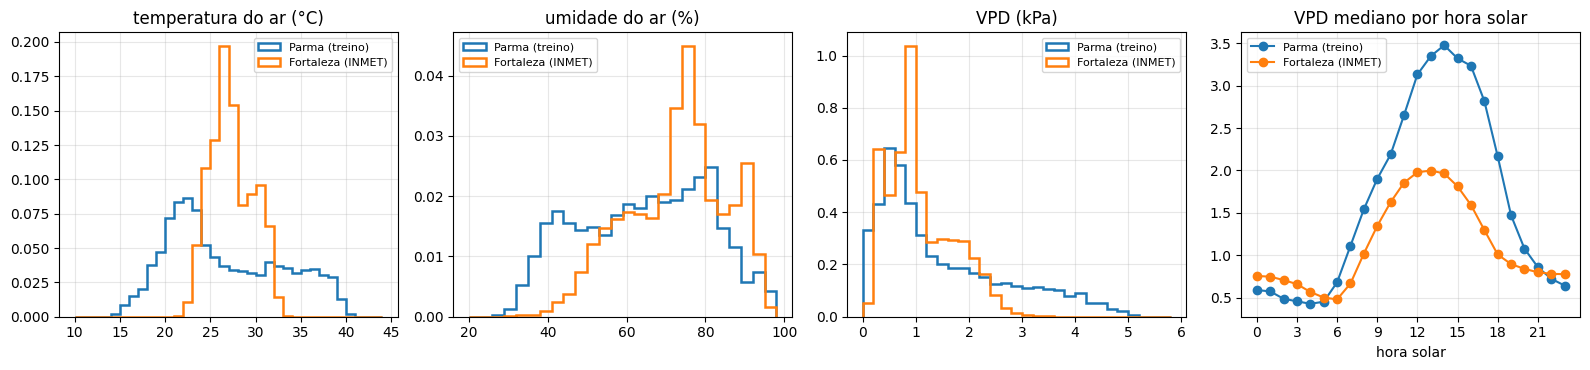

In [22]:
utc_parma = dados.index.tz_convert("UTC")
hora_solar_parma = (utc_parma.hour + utc_parma.minute / 60 + LONGITUDE_PARMA / 15) % 24

fig, eixos = plt.subplots(1, 4, figsize=(16, 3.8))
titulos = {"ar_temperatura": "temperatura do ar (°C)", "ar_umidade": "umidade do ar (%)", "vpd_kpa": "VPD (kPa)"}
bins = {"ar_temperatura": np.arange(10, 45, 1), "ar_umidade": np.arange(20, 101, 3), "vpd_kpa": np.arange(0, 6, 0.2)}

for ax, v in zip(eixos, VARS_AR):
    ax.hist(dados[v].dropna(), bins=bins[v], density=True, histtype="step", lw=1.8, label="Parma (treino)")
    ax.hist(fortaleza[v].dropna(), bins=bins[v], density=True, histtype="step", lw=1.8, label="Fortaleza (INMET)")
    ax.set_title(titulos[v])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

eixos[3].plot(pd.Series(dados["vpd_kpa"].to_numpy(), index=hora_solar_parma.astype(int)).groupby(level=0).median(), marker="o", label="Parma (treino)")
eixos[3].plot(fortaleza.groupby(fortaleza["hora_solar"].astype(int))["vpd_kpa"].median(), marker="o", label="Fortaleza (INMET)")
eixos[3].set(title="VPD mediano por hora solar", xlabel="hora solar", xticks=range(0, 24, 3))
eixos[3].grid(alpha=0.3)
eixos[3].legend(fontsize=8)

fig.tight_layout()
salvar_fig(fig, "08_clima_parma_x_fortaleza.png")
plt.show()

**O que os dados do INMET mostram:**

- **A temperatura quase não muda ao longo do ano:** média de 27 °C, máxima do dia entre 30 e 32 °C.
- **De agosto a outubro está a época mais exigente para irrigação:** à tarde a umidade do ar cai para ~48%, o VPD sobe para 2,3 kPa, venta ~3 m/s e quase não chove (menos de 10 mm por mês).
- **De fevereiro a maio é a época de chuva:** 200 a 450 mm por mês. A umidade do ar fica alta e o VPD mais baixo.

**O modelo vai precisar extrapolar?** Não. 100% das horas de Fortaleza ficam dentro da faixa de temperatura e VPD dos dados de treino, e 99,95% dentro da faixa de umidade do ar.

**A diferença está na intensidade:** a tarde de verão em Parma era mais quente e mais seca (VPD mediano ~3,5 kPa, contra ~2 kPa em Fortaleza). Como o modelo depende pouco das variáveis do ar (seção 6), isso pesa pouco. O que vai mudar de fato é a velocidade de secagem do solo, por causa do solo arenoso e do vento da estação seca, e isso o modelo acompanha pela tendência da umidade.

## 9. Sensor capacitivo v1.2

**Como funciona.** O sensor mede a capacitância entre as trilhas da placa, que muda com a água no solo, e devolve uma tensão: **quanto mais seco, maior a tensão**. Não há eletrodo exposto, então ele não corrói como os sensores resistivos. Mas a leitura depende do tipo de solo, da compactação e de quanto a placa está enterrada, por isso precisa ser calibrado no solo onde vai ficar.

**Ligação no ESP32**

| Sensor | ESP32 |
|---|---|
| VCC | GPIO 25 (liga o sensor só na hora de ler) ou 3V3 |
| GND | GND |
| AOUT | GPIO 34 |

- Use um pino do **ADC1** (GPIO 32 a 39). O ADC2 não funciona com o Wi-Fi ligado.
- Leia várias vezes e tire a média; o ADC do ESP32 é ruidoso.
- Ar: **BME280** no I2C (SDA 21, SCL 22). A placa BMP280 é quase igual, mas **não mede umidade**. Confirme o modelo antes de comprar ou instalar.
- Válvula solenoide ou bomba por relé, com fonte separada. Use uma válvula normalmente fechada, para que uma falha de energia não deixe a irrigação ligada.

**Instalação**

- Enterre só a parte abaixo da linha marcada na placa, na vertical, na zona das raízes, a uns 10 cm da planta e do gotejador.
- Os componentes no topo e as bordas da placa não são à prova d'água. Proteja com termo-retrátil, cola quente ou esmalte, e deixe essa parte fora do solo e na sombra (o sol esquenta a placa e altera a leitura).
- O solo precisa ficar bem encostado na placa, sem bolsas de ar. Se o sensor for tirado do lugar, refaça a calibração.
- A parte sensível tem poucos centímetros, então mede a camada mais superficial. Isso corresponde ao sensor de 15 cm de Parma, que era o gatilho em 2025.

**Calibração (3 leituras)**

1. **Teste de bancada:** anote a tensão com o sensor no ar e com ele mergulhado em água até a linha. Se as duas forem quase iguais, o sensor está com defeito (acontece com alguns clones).
2. **Capacidade de campo (`MV_CC`):** encharque o solo em volta do sensor, cubra para não evaporar e espere a água em excesso drenar (~24 h em vaso, ~48 h em canteiro). Anote a tensão.
3. **Solo seco (`MV_SECO`):** deixe o solo secar sem irrigar até as folhas começarem a murchar nas horas quentes. Anote a tensão.

Com isso, a umidade relativa fica:

$$\text{umidade} = 100 \times \frac{\text{MV\_SECO} - \text{leitura}}{\text{MV\_SECO} - \text{MV\_CC}}$$

com 0 = seco e 100 = capacidade de campo.

**Limiar e escala.** O tomate tolera consumir ~40% da água disponível antes de sofrer estresse (FAO-56, fator p = 0,40). Por isso o **limiar = 60** e a **escala = 100 − 60 = 40**. Depois da primeira semana, recalcule a escala como foi feito com os dados de Parma: a mediana do pico depois de irrigar, menos o limiar.

### Exemplo: o modelo rodando com dados de Fortaleza

A mesma `montar_features` serve para Fortaleza: basta trocar o limiar, a escala e a longitude.

O exemplo usa a temperatura e a umidade do ar **reais** de um dia típico de outubro de 2023 (o INMET mede de hora em hora; os valores são interpolados para 10 min). A umidade do solo é **simulada**, já calibrada em umidade relativa (0 = seco, 100 = capacidade de campo; limiar 60 e escala 40, como na seção 9). Ela começa em 85 às 6h e seca mais rápido quando o VPD está alto.

In [23]:
# dia de outubro de 2023 com as 24 horas medidas e VPD da tarde mais próximo da mediana do mês
outubro = fortaleza[(fortaleza.index.year == 2023) & (fortaleza.index.month == 10)]
horas_ok = outubro[VARS_AR].notna().all(axis=1).groupby(outubro.index.date).sum()
vpd_tarde = outubro[outubro["hora_solar"].between(11, 15)].groupby(lambda d: d.date())["vpd_kpa"].mean()
vpd_tarde = vpd_tarde[vpd_tarde.index.isin(horas_ok[horas_ok == 24].index)]
DIA = (vpd_tarde - vpd_tarde.median()).abs().idxmin()

ar = fortaleza.loc[str(DIA), ["ar_temperatura", "ar_umidade"]].resample("10min").interpolate()
ar = ar.between_time("06:00", "19:00")

secagem_10min = 0.10 + 0.20 * vpd(ar["ar_temperatura"], ar["ar_umidade"])  # pontos de umidade por 10 min
simulado = ar.assign(umidade=85 - secagem_10min.cumsum().shift(fill_value=0), valvula=0)

f_sim = montar_features(simulado, limiar=60, escala=40, longitude=LONGITUDE_FORTALEZA)
simulado["probabilidade"] = prever(f_sim.to_numpy())
simulado["decisao"] = np.where(simulado["umidade"] <= 60, "irrigar (limiar)",
                               np.where(simulado["probabilidade"] >= CORTE, "irrigar (antecipado)", "esperar"))

primeiro_antecipado = simulado.index[simulado["decisao"] == "irrigar (antecipado)"].min()
chegou_limiar = simulado.index[simulado["umidade"] <= 60].min()
print(f"Dia: {DIA}")
print(f"Modelo manda irrigar: {primeiro_antecipado:%H:%M} | umidade chega ao limiar: {chegou_limiar:%H:%M}")

inicio_tabela = primeiro_antecipado - pd.Timedelta("60min")
simulado.loc[inicio_tabela:chegou_limiar + pd.Timedelta("30min"), ["umidade", "ar_temperatura", "ar_umidade", "probabilidade", "decisao"]].round(2)

Dia: 2023-10-27
Modelo manda irrigar: 14:00 | umidade chega ao limiar: 14:40


,umidade,ar_temperatura,ar_umidade,probabilidade,decisao
datetime,,,,,
2023-10-27 13:00:00-03:00,64.99,31.50,53.00,0.00,esperar
2023-10-27 13:10:00-03:00,64.46,31.45,53.00,0.00,esperar
2023-10-27 13:20:00-03:00,63.92,31.40,53.00,0.01,esperar
2023-10-27 13:30:00-03:00,63.39,31.35,53.00,0.05,esperar
2023-10-27 13:40:00-03:00,62.86,31.30,53.00,0.33,esperar
2023-10-27 13:50:00-03:00,62.33,31.25,53.00,0.32,esperar
2023-10-27 14:00:00-03:00,61.80,31.20,53.00,0.89,irrigar (antecipado)
2023-10-27 14:10:00-03:00,61.28,30.98,54.00,0.97,irrigar (antecipado)
2023-10-27 14:20:00-03:00,60.76,30.77,55.00,1.00,irrigar (antecipado)


No dia escolhido (27/10/2023, estação seca) o modelo manda irrigar às 14h00, **40 min antes** de a umidade chegar ao limiar (14h40). A partir do limiar, a regra de segurança assume.

O ar desse exemplo é real, mas a umidade do solo é simulada. O teste de verdade vai ser com os dados do protótipo.

## 10. Como fica no protótipo

O código está em `esp32_irrigacao/esp32_irrigacao.ino` e inclui o `modelo_irrigacao.h` gerado na seção 7. A cada 10 min, o mesmo passo de tempo do treino, o ESP32:

1. lê o sensor de solo e o BME280 e guarda as últimas 3 h de umidade;
2. calcula as 10 features, igual à `montar_features`;
3. decide:
   - umidade ≤ limiar → **irriga** (regra de segurança, igual ao controlador de Parma);
   - já está irrigando e a umidade ainda não passou de limiar + escala/2 → **repete o pulso**;
   - modelo ≥ ponto de corte → **irriga antecipado**;
   - senão → espera;
4. irriga em pulsos curtos (10 min de água, 10 min de espera para infiltrar), com um limite de pulsos por dia;
5. imprime tudo em CSV na Serial, para guardar e retreinar.

Nas primeiras 3 h depois de ligar, ou se o BME280 falhar, só a regra de limiar funciona.

**Plano de uso**

1. **Bancada:** testar o sensor (calibração, passo 1), o BME280 e o relé. O código não foi compilado aqui; compile na Arduino IDE com as bibliotecas indicadas no topo do arquivo.
2. **Semanas 1 e 2:** instalar, calibrar (passos 2 e 3) e rodar. Guardar o CSV.
3. **Ajuste:** recalcular a escala com os dados reais e ajustar a duração do pulso (em solo arenoso, pulsos curtos perdem menos água por drenagem).
4. **Depois de ~1 mês:** retreinar este notebook com os dados de Fortaleza. Basta montar a tabela de entrada (`umidade`, `ar_temperatura`, `ar_umidade`, `valvula`) e trocar a longitude e o fuso.

## 11. Resumo

- **Alvo:** começar uma irrigação nos próximos 60 min, com features relativas ao limiar e hora solar.
- **Modelo:** gradient boosting. Na validação por blocos de dias: AP 0,87 e F1 0,79, avisa 91% das irrigações com 60 min de antecedência, com menos de 1 alarme falso por dia. É bem melhor que as regras simples e que a regressão logística.
- **Generalização:** treinado em um ano e testado no outro (sensor, profundidade e limiar diferentes), mantém AP de 0,83 a 0,86.
- **Clima de Fortaleza:** pelos dados do INMET de 2020 a 2023, as condições de lá ficam dentro da faixa que o modelo viu. A época mais exigente é de agosto a outubro.
- **Exportado** para o ESP32 (200 árvores, ~64 KB), com a conta conferida contra o scikit-learn.
- **Em Fortaleza:** calibrar o sensor no solo do protótipo (limiar 60, escala 40 em umidade relativa), usar a regra de limiar como segurança e o modelo para antecipar. Guardar os dados e retreinar com eles depois de algumas semanas.